### This example tries to replace the original SVM with XGBoost 

## THIS VERSION USES OPTUNA TO FIND BEST PARAMETERS

In [ ]:
# for Optuna:
# pip install optuna

In [1]:
# since we are doing parameter optimization
# it's a good idea to lock down the random seed
import os
import random
import numpy as np
seed = 78115
os.environ['PYTHONHASHSEED'] = str(seed)      
random.seed(seed)                             
np.random.seed(seed)                          

In [2]:
# pip install xgboost

**Otherwise this is the same notebook as the SVM classification example, so some of the comments etc. might not make sense**

#

### SVM classification, example 2, Heart disease prediction, data

In [3]:
# usual imports in a classic ML pipeline for Classification
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# additional metrics ONLY for classification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

# import helpful features like pipelines etc, also SVM!
from sklearn.model_selection import train_test_split
from sklearn import metrics, svm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [4]:
# load the data
df = pd.read_csv("Heart_Disease_Prediction.csv")

# let's quickly see the first 5 rows of data
df

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence


In [5]:
# you can also use LabelEncoder here, but you HAVE MORE CONTROL
# on what is what if you use mapping
target_mapping = {"Absence": 0, "Presence": 1}
df['Heart Disease'] = df['Heart Disease'].map(target_mapping)

In [6]:
# this is a binary variable, need to convert to integers laters
df['Heart Disease'].value_counts()

Heart Disease
0    150
1    120
Name: count, dtype: int64

In [7]:
# check duplicates 
df.duplicated().sum()

np.int64(0)

In [8]:
df.isna().sum()

Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

**Step 2: handle categoricals**

We only have one binary variable, so we don't need to process other types of categoricals.

NOTE: this is actually also the target variable

For target variable, it's allowed to use values like 1,2,3,4 etc.
Even if they seem "nominal", since logistic regression only works with one ouput by default.

**There's no ordinal or nominal categories here, we can proceed to X/y -phase**

In [9]:
df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0


### X/y and train/test -splits

In [10]:
# first step, we split our data into SUPPORT variables and the TARGET variable
# X => support variables, y => target variable

# X => list of support variables the model uses 
# while predicting the target variable with the model
X = df.drop("Heart Disease", axis=1)

# our target variable is y
y = df["Heart Disease"]

**IMPORTANT WHEN OPTIMIZING PARAMETERS!**

Always lock down randomness in your algorithm and data so that your baseline remains the same. If you don't do this, you never know if the model improved because of the parameters or just sheer luck!

Here we only lock down train/test-split. We usually also lock down NumPy random seed + others!

In [11]:
# secondly, train/test -split with scikit-learn's helper function
# 0.3 for testing => 30% of data is reserved for testing purposes
# and based on that => it's deduced that 70% will be in the training data

# you can also define the random state, which is sometimes useful
# if you want to "lock down" all the randomness in order to get same results every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12345)

### USE OPTUNA TO FIND BEST PARAMETERS

In [12]:
# imports needed here
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import optuna
from optuna.exceptions import TrialPruned

# in OPTUNA, we need an objective-function, that contains
# the parameters we want to optimize
def objective(trial):
    # Hyperparameter search space
    n_estimators = trial.suggest_int("n_estimators", 50, 500)
    max_depth = trial.suggest_int("max_depth", 3, 15)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    min_child_weight = trial.suggest_int("min_child_weight", 1, 10)
    subsample = trial.suggest_float("subsample", 0.6, 1.0)
    colsample_bytree = trial.suggest_float("colsample_bytree", 0.6, 1.0)
    gamma = trial.suggest_float("gamma", 0, 5)
    reg_alpha = trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True)
    reg_lambda = trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True)

    # Create XGBoost classifier
    xgb = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        min_child_weight=min_child_weight,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        gamma=gamma,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda,
        n_jobs=1,
        random_state=42,
        seed=seed,
        eval_metric="logloss"
    )

    # Train model
    xgb.fit(X_train, y_train)

    # Evaluate accuracy
    y_pred = xgb.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    # Report result to Optuna and check pruning
    trial.report(accuracy, step=0)

    # use pruning if needed
    if trial.should_prune():
        raise TrialPruned()

    return accuracy


# let's use a separate sampler, so we can lock down
# the randomness in Optuna too
sampler = optuna.samplers.TPESampler(
    seed=seed
)

# Create and run Optuna study
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=500)

# Best result
print("Best trial:")
trial = study.best_trial

print(f"  Accuracy: {trial.value:.4f}")
print("  Best hyperparameters:")

for key, value in trial.params.items():
    print(f"    {key}: {value}")

c:\Users\tuomas.valtanen\MLMethods2026Autumn\MLMethods2026Autumn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-16 08:58:32,354] A new study created in memory with name: no-name-2c88c4c5-944f-4b12-b939-adeefd6f6db5
[I 2026-11-16 08:58:32,625] Trial 0 finished with value: 0.8024691358024691 and parameters: {'n_estimators': 93, 'max_depth': 5, 'learning_rate': 0.079817864293462, 'min_child_weight': 4, 'subsample': 0.693168411077415, 'colsample_bytree': 0.9703487557702996, 'gamma': 1.3590022364804883, 'reg_alpha': 0.02781230412806644, 'reg_lambda': 0.6926652993598924}. Best is trial 0 with value: 0.8024691358024691.
[I 2026-11-16 08:58:32,645] Trial 1 finished with value: 0.7777777777777778 and parameters: {'n_estimators': 178, 'max_depth': 13, 'learning_rate': 0.27698260720027235, 'min_child_weight

Best trial:
  Accuracy: 0.8642
  Best hyperparameters:
    n_estimators: 155
    max_depth: 8
    learning_rate: 0.15518474641934854
    min_child_weight: 2
    subsample: 0.8680293755970191
    colsample_bytree: 0.8160893893745588
    gamma: 4.190110200195365
    reg_alpha: 0.28915882712104746
    reg_lambda: 0.00048797193522213803


### Train the SVC model

**Here we try XGBoost instead of SVC**

In [15]:
# create the model and train it with the data
from xgboost import XGBClassifier

# if you wish to use LinearSVC => we need to wrap it into a
# CalibratedClassifierCV so it outputs probabilities for the metrics
# model = make_pipeline(StandardScaler(), CalibratedClassifierCV(svm.LinearSVC()))

# n_estimators: 155
#     max_depth: 8
#     learning_rate: 0.15518474641934854
#     min_child_weight: 2
#     subsample: 0.8680293755970191
#     colsample_bytree: 0.8160893893745588
#     gamma: 4.190110200195365
#     reg_alpha: 0.28915882712104746
#     reg_lambda: 0.00048797193522213803

# Pipeline is super helpful here, since we can integrate the scaler
# before the model, no need to manually scale anything
model = make_pipeline(StandardScaler(), XGBClassifier(
        n_estimators=155,
        max_depth=8,
        learning_rate=0.15518474641934854,
        min_child_weight=2,
        subsample=0.8680293755970191,
        colsample_bytree=0.8160893893745588,
        gamma=4.190110200195365,
        reg_alpha=0.28915882712104746,
        reg_lambda=0.00048797193522213803,
        n_jobs=1,
        random_state=42,
        seed=seed,
        eval_metric="logloss"
    ))

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','Sex','Chest pain type',...,'Slope of ST','Number of vessels fluro', 'Thallium']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Classification error metrics

In [16]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = model.predict(X_test)

### EXTRA: cross validation allows us to see how stable our model is

Cross-validation usually makes a few (often 3-5) random splits of the testing dataset, and runs the metrics against each => take average metrics from all of them

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted",
    "roc_auc": "roc_auc_ovr_weighted"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# Display results
print("\nCross-validation results:")

for metric in scoring.keys():

    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():12s}: "
        f"{scores.mean():.4f} (+/- {scores.std():.4f})"
    )


Cross-validation results:
ACCURACY    : 0.8256 (+/- 0.0537)
PRECISION   : 0.8262 (+/- 0.0551)
RECALL      : 0.8256 (+/- 0.0537)
F1          : 0.8250 (+/- 0.0539)
ROC_AUC     : 0.8820 (+/- 0.0485)


The model is pretty unstable now, we need to probably lock down the random seed in this notebook and find optimal parameters for the XGBoost as well.

Accuracies are between 75 - 83% typically with the current notebook.

In [ ]:
# print the classification report based on true values and predictions
print(classification_report(y_test, predictions))

# get overall accuracy of the model and print it
acc = accuracy_score(y_test, predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

              precision    recall  f1-score   support

           0       0.83      0.93      0.88        42
           1       0.91      0.79      0.85        39

    accuracy                           0.86        81
   macro avg       0.87      0.86      0.86        81
weighted avg       0.87      0.86      0.86        81


Model overall accuracy: 86.42%


<Axes: >

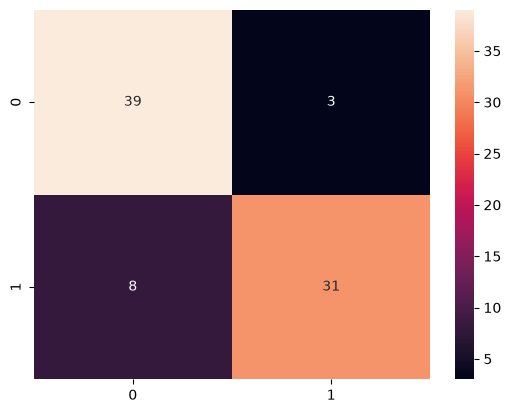

In [ ]:
# see the confusion matrix
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='g')


In [ ]:
# The AUC score is a super sensitive metric
# you often get low scores, even 0.5

# in binary logistic regression, AUC values are often interpreted as follows:
# A binary classifier is useful only when it achieves ROC-AUC score greater than 0.5 and as near to 1 as possible. 
# If a classifier yields a score less than 0.5, it simply means that the model is performing worse 
# than a random classifier, and therefore is useless.

# In multinomial logistic regression , AUC values are often interpreted as follows: 
# 0.5-0.6 (failed)
# 0.6-0.7 (worthless)
# 0.7-0.8 (poor)
# 0.8-0.9 (good)
# > 0.9 (excellent)

# basically 0.5 means you could get the same result with just random guessing
roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

0.9044566544566545

### Using the model in practice

In [ ]:
df.columns

Index(['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120',
       'EKG results', 'Max HR', 'Exercise angina', 'ST depression',
       'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease'],
      dtype='str')

In [ ]:
# usually in GUI application we save the model-object / variable into a file (by using joblib-module)
# and in the GUI application => we load the saved model from the file
# and use the model just like here below


# map all the variables from the user
# into a Python dictionary
# the variable names have to match with the original dataset
tester_row = {
    'Age': 36, 
    'Sex': 0, 
    'Chest pain type': 4, 
    'BP': 120, 
    'Cholesterol': 500, 
    'FBS over 120': 0,
    'EKG results': 1, 
    'Max HR': 140, 
    'Exercise angina': 1, 
    'ST depression': 1,
    'Slope of ST': 2, 
    'Number of vessels fluro': 3, 
    'Thallium': 7
}

# convert to pandas format
tester_row = pd.DataFrame([tester_row])


**Notice here:** if you have something else than 0/1/2 etc. as the target variable (like text, Yes/No), modify the following part so that we just print the plain output from the model.

In [ ]:
# get labels from the dataset directly
labels = np.unique(df['Heart Disease'])

# show the probabilities with the target names
print("All probabilities by category:")
print(labels)
print(model.predict_proba(tester_row))
print()

# change these based on your original data
# no need to this since our data already has the labels in the target
# labels = ["No", "Yes"]

print("Does this person have the heart disease:")

# our target variable is in text format (Presence/Absent)
# just print it as it is
# result = labels[model.predict(tester_row)[0]]
result = model.predict(tester_row)[0]
print(result)
print("-------------------")

All probabilities by category:
[0 1]
[[0.13713962 0.8628604 ]]

Does this person have the heart disease:
1
-------------------
